# Imports

# Dataloading

## Como juntar originais e sintéticos por fold

A ideia é manter o `k_fold_splits.json` como fonte de verdade para os dados reais e usar a metadata dos tars sintéticos para escolher apenas os shards que pertencem ao fold de treino.

No treino:
- os dados reais entram pelo fold atual
- os dados sintéticos entram apenas se a `strategy_metadata.json` disser que aquele fold está em `train_folds`
- validação e teste ficam só com dados reais para evitar leakage

In [15]:
from pathlib import Path
import json
from pprint import pprint
from typing import Dict, List, Tuple

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

project_root = Path('/home/win11/attention-cim')
data_root = project_root / 'data'
class_name = 'metaplasia'
strategy_name = 'strategy1'
techniques = 'our_approach'
multiplier = '1x'

augmented_root = data_root / 'augmented' / class_name
local_class_root = data_root / class_name
strategy_root = augmented_root / techniques / multiplier / strategy_name
strategy_metadata_path = strategy_root / 'strategy_metadata.json'
synthetic_tar_path = strategy_root / f'{class_name}_{multiplier}_{techniques}.tar'
kfold_splits_path = augmented_root / 'k_fold_splits.json'

print(f'Project root: {project_root}')
print(f'Class: {class_name}')
print(f'Strategy: {strategy_name}')
print(f'Strategy metadata: {strategy_metadata_path}')
print(f'Synthetic tar: {synthetic_tar_path}')
print(f'Local data root: {local_class_root}')
print(f'K-fold splits: {kfold_splits_path}')


def load_json(path: Path) -> dict:
    with open(path, 'r') as handle:
        return json.load(handle)


def list_image_files(folder: Path) -> List[Path]:
    if not folder.exists():
        return []
    files = []
    for pattern in ('*.png', '*.jpg', '*.jpeg', '*.JPG', '*.JPEG', '*.PNG'):
        files.extend(folder.glob(pattern))
    return sorted(set(files))


def resolve_fold_indices(splits_data: dict, fold_names: List[str]) -> Tuple[List[int], List[int]]:
    instance_indices = []
    normal_indices = []

    for fold_name in fold_names:
        fold_data = splits_data['folds'][fold_name]
        instance_key = 'instance_idxs' if 'instance_idxs' in fold_data else 'train_instance_indices'
        normal_key = 'normal_idxs' if 'normal_idxs' in fold_data else 'train_normal_indices'
        instance_indices.extend(fold_data.get(instance_key, []))
        normal_indices.extend(fold_data.get(normal_key, []))

    return sorted(set(instance_indices)), sorted(set(normal_indices))


def build_local_fold_subset(local_root: Path, splits_data: dict, fold_names: List[str]) -> dict:
    instance_images = list_image_files(local_root / class_name / 'images')
    instance_masks = list_image_files(local_root / class_name / 'masks')
    normal_images = list_image_files(local_root / 'normal')

    instance_indices, normal_indices = resolve_fold_indices(splits_data, fold_names)

    selected_instance_images = [instance_images[index] for index in instance_indices]
    selected_instance_masks = []
    for image_path in selected_instance_images:
        mask_path = next((mask for mask in instance_masks if mask.stem == image_path.stem), None)
        selected_instance_masks.append(mask_path)

    selected_normal_images = [normal_images[index] for index in normal_indices]

    return {
        'instance_indices': instance_indices,
        'normal_indices': normal_indices,
        'instance_images': selected_instance_images,
        'instance_masks': selected_instance_masks,
        'normal_images': selected_normal_images,
    }


def build_strategy_fold_selection(local_root: Path, strategy_meta: dict, splits_data: dict) -> dict:
    train_folds = strategy_meta['train_folds']
    val_fold = strategy_meta['val_fold']
    test_fold = strategy_meta['test_fold']

    return {
        'strategy_id': strategy_meta['strategy_id'],
        'train_folds': train_folds,
        'val_fold': val_fold,
        'test_fold': test_fold,
        'train': build_local_fold_subset(local_root, splits_data, train_folds),
        'val': build_local_fold_subset(local_root, splits_data, [val_fold]),
        'test': build_local_fold_subset(local_root, splits_data, [test_fold]),
    }


def preview_webdataset_tar(tar_path: Path, max_samples: int = 2) -> List[dict]:
    import webdataset as wds

    dataset = wds.WebDataset(str(tar_path), shardshuffle=False).decode('pil')
    preview = []
    for sample in dataset:
        sample_keys = list(sample.keys())
        preview.append({'keys': sample_keys, 'metadata': sample.get('json', {})})
        if len(preview) >= max_samples:
            break
    return preview


Project root: /home/win11/attention-cim
Class: metaplasia
Strategy: strategy1
Strategy metadata: /home/win11/attention-cim/data/augmented/metaplasia/our_approach/1x/strategy1/strategy_metadata.json
Synthetic tar: /home/win11/attention-cim/data/augmented/metaplasia/our_approach/1x/strategy1/metaplasia_1x_our_approach.tar
Local data root: /home/win11/attention-cim/data/metaplasia
K-fold splits: /home/win11/attention-cim/data/augmented/metaplasia/k_fold_splits.json


In [16]:
strategy_metadata = load_json(strategy_metadata_path)
kfold_splits = load_json(kfold_splits_path)

print('\nStrategy metadata:')
pprint(strategy_metadata)

print('\nTrain folds for this strategy:')
print(strategy_metadata['train_folds'])
print(f"Validation fold: {strategy_metadata['val_fold']}")
print(f"Test fold: {strategy_metadata['test_fold']}")

fold_selection = build_strategy_fold_selection(local_class_root, strategy_metadata, kfold_splits)

print('\nLocal indices selected for training:')
print(f"Instance indices ({len(fold_selection['train']['instance_indices'])}):")
pprint(fold_selection['train']['instance_indices'])
print(f"Normal indices ({len(fold_selection['train']['normal_indices'])}):")
pprint(fold_selection['train']['normal_indices'])

print('\nLocal samples selected for training:')
print(f"Instance images: {len(fold_selection['train']['instance_images'])}")
print(f"Normal images: {len(fold_selection['train']['normal_images'])}")

print('\nSynthetic tar preview:')
pprint(preview_webdataset_tar(synthetic_tar_path, max_samples=2))



Strategy metadata:
{'multiplier': '1x',
 'strategy_id': 1,
 'technique': 'our_approach',
 'test_fold': 'fold1',
 'train_folds': ['fold3', 'fold4', 'fold5'],
 'val_fold': 'fold2'}

Train folds for this strategy:
['fold3', 'fold4', 'fold5']
Validation fold: fold2
Test fold: fold1

Local indices selected for training:
Instance indices (99):
[0,
 1,
 3,
 5,
 7,
 8,
 13,
 14,
 17,
 20,
 21,
 23,
 25,
 28,
 33,
 34,
 35,
 37,
 39,
 40,
 43,
 44,
 46,
 47,
 48,
 49,
 50,
 52,
 53,
 54,
 57,
 58,
 59,
 61,
 62,
 63,
 64,
 70,
 71,
 72,
 73,
 74,
 77,
 79,
 80,
 81,
 83,
 84,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 99,
 102,
 103,
 106,
 107,
 110,
 111,
 113,
 114,
 115,
 116,
 117,
 121,
 122,
 123,
 124,
 125,
 127,
 128,
 129,
 130,
 134,
 137,
 138,
 139,
 142,
 145,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 159,
 161,
 162,
 163,
 164,
 165,
 166]
Normal indices (313):
[1,
 4,
 8,
 12,
 13,
 14,
 20,
 21,
 27,
 28,
 32,
 34,
 35,
 36,
 38,
 40,
 41,
 43,
 44,
 47,
 48,
 49,

In [17]:
import torch
import webdataset as wds
from torch.utils.data import ConcatDataset, Dataset, DataLoader

image_size = 512
batch_size = 8
num_workers = 4


def build_image_transform(size: int = 512):
    return transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
    ])


class LocalBinaryClassificationDataset(Dataset):
    def __init__(self, image_paths, label, transform=None):
        self.samples = [(Path(path), label) for path in image_paths]
        self.transform = transform or build_image_transform(image_size)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]
        image = Image.open(image_path).convert('RGB')
        image = self.transform(image)
        return {
            'image': image,
            'label': torch.tensor(label, dtype=torch.long),
            'path': str(image_path),
            'source': 'local',
        }


class SyntheticTarClassificationDataset(Dataset):
    def __init__(self, tar_path, strategy_id=None, train_folds=None, transform=None):
        self.transform = transform or build_image_transform(image_size)
        self.samples = []

        synthetic_iter = wds.WebDataset(str(tar_path), shardshuffle=False).decode('pil')
        allowed_folds = set(train_folds or [])

        for sample in synthetic_iter:
            metadata = sample.get('json', {}) or {}
            sample_strategy = metadata.get('strategy')
            sample_role = metadata.get('strategy_role')
            sample_train_folds = set(metadata.get('train_folds', []))

            if strategy_id is not None and sample_strategy != strategy_id:
                continue
            if allowed_folds and not sample_train_folds.intersection(allowed_folds):
                continue
            if sample_role is not None and sample_role != 'train':
                continue

            self.samples.append({
                'image': sample['jpg'],
                'metadata': metadata,
                'path': metadata.get('source_id', metadata.get('target_id', 'synthetic')),
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        sample = self.samples[index]
        image = sample['image']
        if not isinstance(image, Image.Image):
            image = Image.fromarray(image)
        image = self.transform(image.convert('RGB'))
        return {
            'image': image,
            'label': torch.tensor(1, dtype=torch.long),
            'path': sample['path'],
            'metadata': sample['metadata'],
            'source': 'synthetic',
        }


def make_local_split_dataset(split_name: str, label_name: str, selection: dict, transform=None):
    if label_name == 'positive':
        image_paths = selection['instance_images']
        label = 1
    else:
        image_paths = selection['normal_images']
        label = 0
    return LocalBinaryClassificationDataset(image_paths, label=label, transform=transform)


transform = build_image_transform(image_size)

train_selection = fold_selection['train']
val_selection = fold_selection['val']
test_selection = fold_selection['test']

train_real_positive = make_local_split_dataset('train', 'positive', train_selection, transform=transform)
train_real_negative = make_local_split_dataset('train', 'negative', train_selection, transform=transform)
val_positive = make_local_split_dataset('val', 'positive', val_selection, transform=transform)
val_negative = make_local_split_dataset('val', 'negative', val_selection, transform=transform)
test_positive = make_local_split_dataset('test', 'positive', test_selection, transform=transform)
test_negative = make_local_split_dataset('test', 'negative', test_selection, transform=transform)

train_synthetic = SyntheticTarClassificationDataset(
    synthetic_tar_path,
    strategy_id=fold_selection['strategy_id'],
    train_folds=fold_selection['train_folds'],
    transform=transform,
)

train_dataset = ConcatDataset([train_real_negative, train_real_positive, train_synthetic])
val_dataset = ConcatDataset([val_negative, val_positive])
test_dataset = ConcatDataset([test_negative, test_positive])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

print('Train dataset sizes:')
print(f'  real negative: {len(train_real_negative)}')
print(f'  real positive: {len(train_real_positive)}')
print(f'  synthetic: {len(train_synthetic)}')
print(f'  total train: {len(train_dataset)}')
print('\nValidation dataset size:')
print(f'  total val: {len(val_dataset)}')
print('\nTest dataset size:')
print(f'  total test: {len(test_dataset)}')


Train dataset sizes:
  real negative: 313
  real positive: 99
  synthetic: 313
  total train: 725

Validation dataset size:
  total val: 139

Test dataset size:
  total test: 139


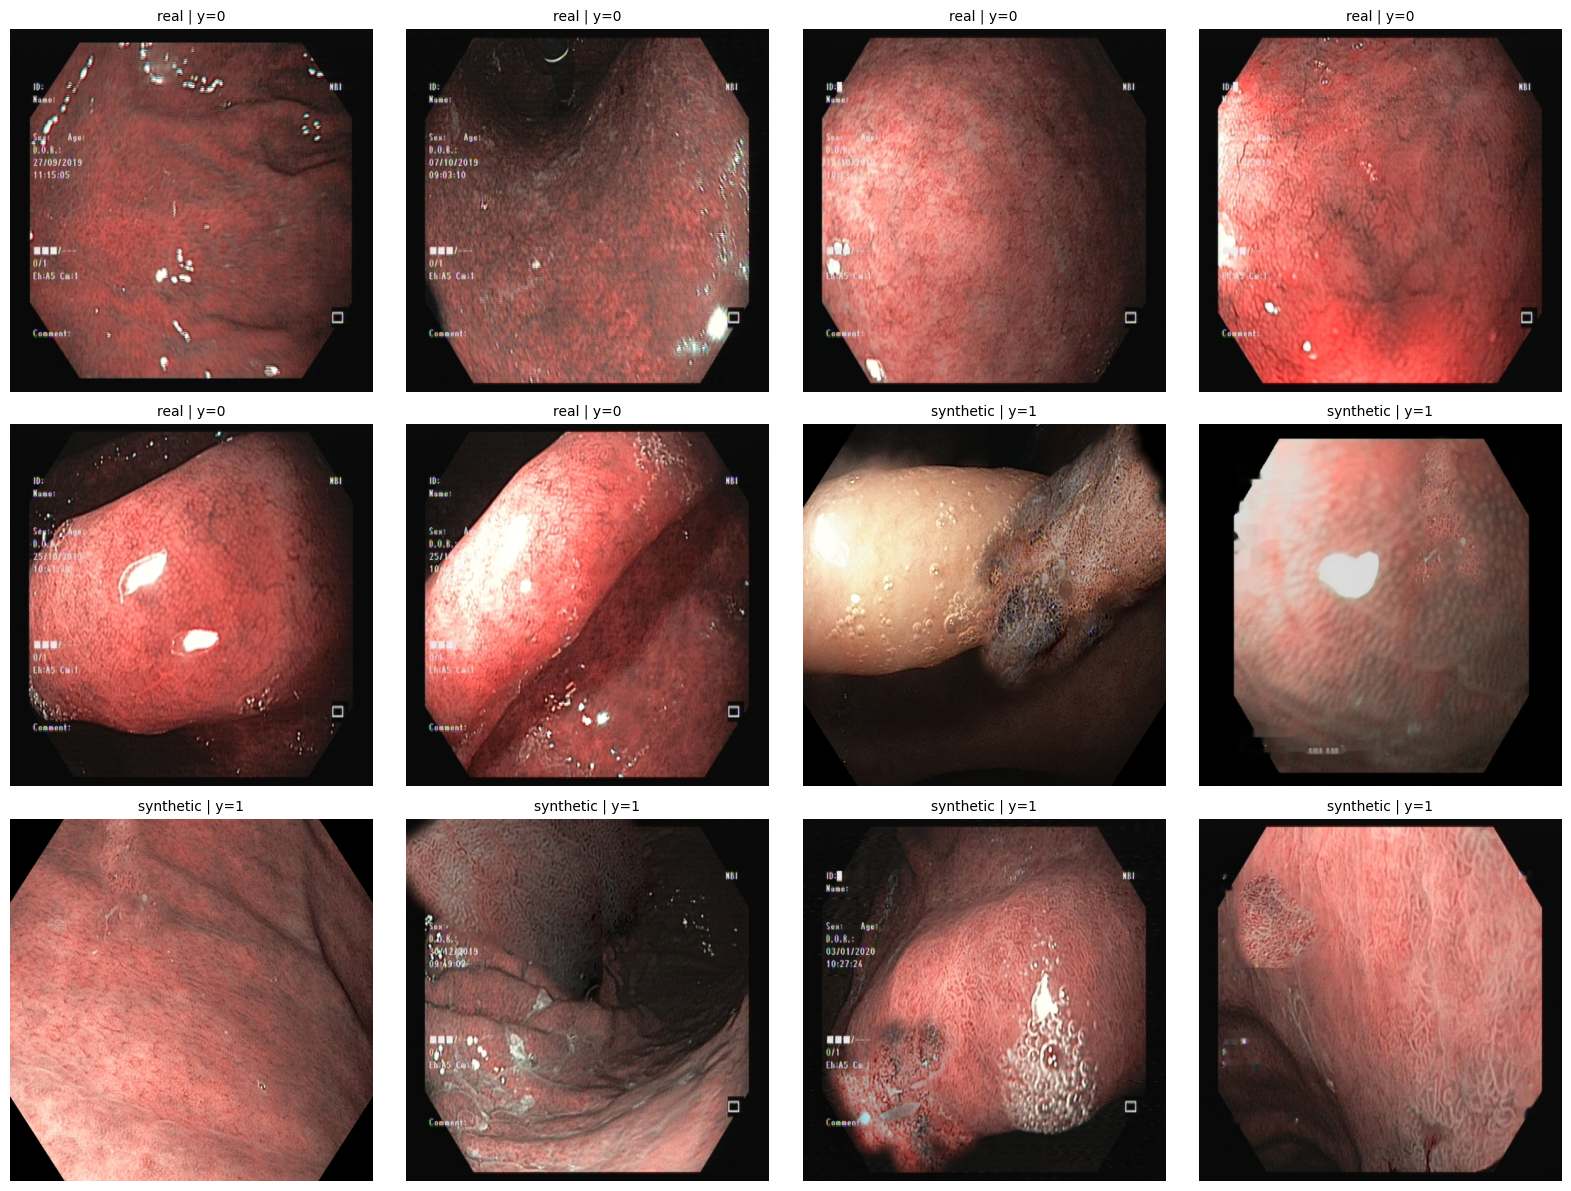

In [18]:
import math
import matplotlib.pyplot as plt
import torch.nn as nn
import torchvision.models as models


def denormalize_tensor(image_tensor):
    return image_tensor.clamp(0, 1).permute(1, 2, 0).cpu().numpy()


def show_train_examples(dataset, max_samples=12, cols=4):
    synthetic_examples = []
    real_examples = []

    for index in range(len(dataset)):
        sample = dataset[index]
        if sample.get('source') == 'synthetic' and len(synthetic_examples) < max_samples // 2:
            synthetic_examples.append(sample)
        elif sample.get('source') == 'local' and len(real_examples) < max_samples // 2:
            real_examples.append(sample)
        if len(synthetic_examples) >= max_samples // 2 and len(real_examples) >= max_samples // 2:
            break

    examples = real_examples + synthetic_examples
    total = len(examples)
    rows = max(1, math.ceil(total / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

    for axis in axes[total:]:
        axis.axis('off')

    for axis, sample in zip(axes, examples):
        axis.imshow(denormalize_tensor(sample['image']))
        label = 'synthetic' if sample['source'] == 'synthetic' else 'real'
        axis.set_title(f"{label} | y={int(sample['label'])}", fontsize=10)
        axis.axis('off')

    plt.tight_layout()
    plt.show()


show_train_examples(train_dataset, max_samples=12, cols=4)


In [ ]:
class ResNet34BinaryClassifier(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = models.ResNet34_Weights.DEFAULT if pretrained else None
        self.backbone = models.resnet34(weights=weights)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, 2)

    def forward(self, x):
        return self.backbone(x)



def set_backbone_trainable(model, train_backbone: bool):
    for parameter in model.backbone.parameters():
        parameter.requires_grad = train_backbone
    for parameter in model.backbone.fc.parameters():
        parameter.requires_grad = True



def run_epoch(model, loader, criterion, optimizer=None, device='cpu'):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch in loader:
        images = batch['image'].to(device)
        labels = batch['label'].to(device)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_samples += images.size(0)

    return {
        'loss': total_loss / max(total_samples, 1),
        'accuracy': total_correct / max(total_samples, 1),
    }


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ResNet34BinaryClassifier(pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()

print(f'Device: {device}')
print('Stage 1: feature extractor warmup with ImageNet weights')

set_backbone_trainable(model, train_backbone=False)
optimizer = torch.optim.AdamW(model.backbone.fc.parameters(), lr=1e-3, weight_decay=1e-4)

warmup_epochs = 1
fine_tune_epochs = 1
best_val_loss = float('inf')
best_state_dict = None
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
}

for epoch in range(warmup_epochs):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer=optimizer, device=device)
    val_metrics = run_epoch(model, val_loader, criterion, optimizer=None, device=device)

    history['train_loss'].append(train_metrics['loss'])
    history['train_acc'].append(train_metrics['accuracy'])
    history['val_loss'].append(val_metrics['loss'])
    history['val_acc'].append(val_metrics['accuracy'])

    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        best_state_dict = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    print(
        f"Warmup epoch {epoch + 1}/{warmup_epochs} | "
        f"train loss={train_metrics['loss']:.4f} acc={train_metrics['accuracy']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} acc={val_metrics['accuracy']:.4f}"
    )

print('Stage 2: fine-tuning the backbone')
set_backbone_trainable(model, train_backbone=True)
optimizer = torch.optim.AdamW(
    [
        {'params': model.backbone.layer4.parameters(), 'lr': 1e-4},
        {'params': model.backbone.fc.parameters(), 'lr': 1e-4},
    ],
    weight_decay=1e-4,
)

for epoch in range(fine_tune_epochs):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer=optimizer, device=device)
    val_metrics = run_epoch(model, val_loader, criterion, optimizer=None, device=device)

    history['train_loss'].append(train_metrics['loss'])
    history['train_acc'].append(train_metrics['accuracy'])
    history['val_loss'].append(val_metrics['loss'])
    history['val_acc'].append(val_metrics['accuracy'])

    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        best_state_dict = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    print(
        f"Fine-tune epoch {epoch + 1}/{fine_tune_epochs} | "
        f"train loss={train_metrics['loss']:.4f} acc={train_metrics['accuracy']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} acc={val_metrics['accuracy']:.4f}"
    )

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)

val_metrics = run_epoch(model, val_loader, criterion, optimizer=None, device=device)
test_metrics = run_epoch(model, test_loader, criterion, optimizer=None, device=device)

print('\nFinal metrics:')
print(f"  val  | loss={val_metrics['loss']:.4f} acc={val_metrics['accuracy']:.4f}")
print(f"  test | loss={test_metrics['loss']:.4f} acc={test_metrics['accuracy']:.4f}")
